In [ ]:
!pip install -q -U bitsandbytes transformers accelerate

Restart

In [2]:
!git clone https://github.com/saloni644c/knee-abnormality.git

fatal: destination path 'knee-abnormality' already exists and is not an empty directory.


In [ ]:
%cd /kaggle/working/knee-abnormality
!git pull

In [ ]:

import sys
from pathlib import Path

PROJECT_ROOT = Path("/kaggle/working/knee-abnormality")
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root exists:", PROJECT_ROOT.exists())
print("Source folder exists:", (PROJECT_ROOT / "src").exists())


from src.config import (
    MODEL_PATH,
    REPORTS_CSV,
    GOLD_CSV,
    ID_COL,
    TEXT_COL,
    FINDINGS,
    MAX_NEW_TOKENS,
    USE_4BIT,
    OUT_PATH,
)

from src.data import *
from src.model import ReportLabelModel
from src.extraction import extract_gold_labels, extract_non_gold_labels
from src.evaluation import evaluate_predictions

print("Project root:", PROJECT_ROOT)
print("Number of findings:", len(FINDINGS))

In [ ]:
from src.data import *
from src.model import ReportLabelModel
from src.extraction import (
    extract_gold_labels,
    extract_non_gold_labels,
)
from src.evaluation import evaluate_predictions

print("All module imports successful.")

Load dataset

In [ ]:
import pandas as pd

from src.config import REPORTS_CSV, ID_COL, TEXT_COL, FINDINGS

# Load the training dataset
reports_df = pd.read_csv(REPORTS_CSV)

print("Dataset shape:", reports_df.shape)
print("\nColumn names:")
print(reports_df.columns.tolist())

print("\nFirst 5 rows:")
display(reports_df.head())

print("\nMissing reports:", reports_df[TEXT_COL].isna().sum())
print("Unique study IDs:", reports_df[ID_COL].nunique())

# Identify fully gold-labelled studies
gold_mask = reports_df[FINDINGS].notna().all(axis=1)

print("\nGold-labelled studies:", int(gold_mask.sum()))
print("Remaining studies:", int((~gold_mask).sum()))

In [ ]:
# Authenticate without storing a token in the notebook.
# In Kaggle, add a secret named HF_TOKEN in Add-ons > Secrets.
import os
from huggingface_hub import login

hf_token = os.environ.get('HF_TOKEN')
if not hf_token:
    try:
        from kaggle_secrets import UserSecretsClient
        hf_token = UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        hf_token = None

if hf_token:
    login(token=hf_token)
    print('Hugging Face authentication successful.')
else:
    print('HF_TOKEN not found. If the model is gated, add HF_TOKEN to Kaggle Secrets before loading it.')


In [ ]:
import torch

from src.config import MODEL_PATH, USE_4BIT
from src.model import ReportLabelModel

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Load MedGemma
report_model = ReportLabelModel(
    model_path=MODEL_PATH,
    use_4bit=USE_4BIT,
)

model = report_model.model
processor = report_model.processor

print("\nMedGemma loaded successfully.")

In [ ]:
#Run for 2
from src.generate import generate_batch
from src.parse import parse_output
from src.decision import to_binary
from src.config import FINDINGS, MAX_NEW_TOKENS

# Select two reports with text
test_df = (
    reports_df
    .dropna(subset=[TEXT_COL])
    .head(2)
)

test_texts = test_df[TEXT_COL].astype(str).tolist()

# Generate predictions
raw_outputs = generate_batch(
    test_texts,
    model,
    processor,
    max_new_tokens=MAX_NEW_TOKENS,
)

print("Reports tested:", len(raw_outputs))

for i, raw in enumerate(raw_outputs):
    print(f"\n{'=' * 60}")
    print(f"REPORT {i + 1}")
    print("=" * 60)

    print("\nRaw model output:")
    print(raw)

    parsed, n_bad, parse_ok = parse_output(raw)

    print("\nParsing successful:", parse_ok)
    print("Invalid findings:", n_bad)

    if parse_ok:
        binary_predictions = {
            finding: to_binary(finding, parsed[finding])
            for finding in FINDINGS
        }

        print("\nBinary predictions:")
        print(binary_predictions)

In [ ]:
# Select gold-labelled studies
gold_df = (
    reports_df.loc[reports_df[FINDINGS].notna().all(axis=1)]
    .dropna(subset=[TEXT_COL])
    .drop_duplicates(subset=[ID_COL])
    .reset_index(drop=True)
)

# Limit the test to 10 studies
gold_test_df = gold_df.head(10).copy()

print("Gold studies available:", len(gold_df))
print("Studies selected for testing:", len(gold_test_df))
print("Batch size: 5")
print("Expected batches:", (len(gold_test_df) + 4) // 5)


from src.extraction import extract_gold_labels
from src.config import MAX_NEW_TOKENS

gold_records = extract_gold_labels(
    gold_df=gold_test_df,
    model=model,
    processor=processor,
    batch_size=5,
    max_new_tokens=MAX_NEW_TOKENS,
    output_path="/kaggle/working/gold_predictions_test.jsonl",
)

print("Reports processed:", len(gold_records))

In [ ]:
from src.evaluation import evaluate_predictions

scores_df, summary_df, injury_summary = evaluate_predictions(
    batch_records=gold_records,
    gold_df=gold_test_df,
)

print("OVERALL SUMMARY")
display(summary_df)

print("RESULTS BY FINDING")
display(injury_summary)

In [ ]:
MIN_SEVERITY = {f: "mild" for f in FINDINGS}

MIN_SEVERITY.update({
    "Medial OA": "severe",
    "Lateral OA": "severe",
    "PF OA": "severe",
})

# Inspect model outputs for the problematic findings

problem_findings = [
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Synovitis",
    "Baker's",
    "Fracture",
]

for record in gold_records:
    print("\n" + "=" * 80)
    print("Study ID:", record[ID_COL])

    print("\nGold labels:")
    gold_row = gold_test_df.loc[
        gold_test_df[ID_COL] == record[ID_COL]
    ].iloc[0]

    for finding in problem_findings:
        print(f"  {finding}: {gold_row[finding]}")

    print("\nMedGemma predictions:")
    for finding in problem_findings:
        entry = record["parsed"][finding]
        prediction = record["predictions"][finding]

        print(
            f"  {finding}: "
            f"state={entry['state']}, "
            f"severity={entry['severity']}, "
            f"binary={prediction}, "
            f"evidence={entry['evidence']}"
        )
        

In [ ]:
from src.extraction import extract_gold_labels
from src.evaluation import evaluate_predictions
from src.config import ID_COL, FINDINGS, MAX_NEW_TOKENS

# Select studies with all 12 existing labels
gold_df = (
    reports_df.loc[reports_df[FINDINGS].notna().all(axis=1)]
    .dropna(subset=[TEXT_COL])
    .drop_duplicates(subset=[ID_COL])
    .reset_index(drop=True)
)

print("Gold studies available:", len(gold_df))

# Extract MedGemma predictions
gold_records = extract_gold_labels(
    gold_df=gold_df,
    model=model,
    processor=processor,
    batch_size=5,
    max_new_tokens=MAX_NEW_TOKENS,
    output_path="/kaggle/working/gold_predictions.jsonl",
)

print("\nReports processed:", len(gold_records))

# non-gold labels extraction 

In [ ]:

from src.extraction import extract_non_gold_labels

extract_non_gold_labels(
    reports_df=reports_df,
    model=model,
    processor=processor,
    batch_size=5,
    start_index=50,
    end_index=70,
    pseudo_labels_csv="/kaggle/working/pseudo_labels.csv",
    error_log_jsonl="/kaggle/working/pseudo_label_errors.jsonl",
)


In [ ]:
with open("/kaggle/working/pseudo_label_errors1.jsonl") as f:
    errors = [json.loads(line) for line in f if line.strip()]

print("Logged errors:", len(errors))
print("Invalid fields:", errors[0]["n_bad"])
print(errors[0]["raw_output"])

trying to fix the failed issue 

In [ ]:
NEW_SYSTEM_PROMPT = """
You are a radiology report reader for knee MRI reports.

Read the report in its original language. Do not translate it.
Extract only findings supported by the report.

For each of the 12 findings, return state, severity, and evidence.

FINDINGS:
ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA,
Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture.

STATE (choose one):
- present: The report describes the finding as present.
- absent: The report explicitly describes the finding as normal, intact, or absent.
- uncertain: The report uses hedged wording, such as possible, probable,
  suspected, cannot exclude, or suggestive of.
- not_mentioned: The report does not discuss the finding.

SEVERITY (choose one):
none, mild, moderate, severe, unspecified.

Severity mapping:
- If the report explicitly states mild, moderate, or severe, use that category.
- If the report uses another severity descriptor (e.g., trace, minimal,
  small, low-grade), map it according to the finding-specific rules
  defined below.
- Do not automatically map these terms to mild across all findings.
- If no validated mapping exists for a descriptor and finding, use
  unspecified rather than guessing.
  
EVIDENCE:
Provide a short exact quote of fewer than 15 words from the report
in its original language.
Use an empty string when state is not_mentioned.

OUTPUT FORMAT:
Return one valid JSON object, not a list.

Use exactly these 12 top-level keys:
"ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
"Medial OA", "Lateral OA", "PF OA", "Effusion",
"Synovitis", "Baker's", "Contusion", "Fracture".

Each key must contain exactly these fields:
- "state": "present", "absent", "uncertain", or "not_mentioned"
- "severity": "none", "mild", "moderate", "severe", or "unspecified"
- "evidence": a short string

Use lowercase field names. Do not use Markdown code fences.
Return JSON only.

"""

In [ ]:
import src.prompt as prompt
import time
import src.generate as generate
from src.parse import parse_output
from src.config import FINDINGS, ID_COL, TEXT_COL
from src.decision import to_binary
import pandas as pd

# Preserve the currently installed prompt
original_prompt = prompt.SYSTEM_PROMPT

gold_df = reports_df.dropna(subset=FINDINGS).copy().reset_index(drop=True)

results = []
parse_failures = []
start_time = time.time()

try:
    prompt.SYSTEM_PROMPT = NEW_SYSTEM_PROMPT

    for i, row in gold_df.iterrows():
        try:
            raw = generate.generate_one(
                report_text=row[TEXT_COL],
                model=model,
                processor=processor,
            )

            parsed, n_bad, parse_ok = parse_output(raw)

            prediction = {
                finding: to_binary(finding, parsed[finding])
                for finding in FINDINGS
            }

            results.append({
                ID_COL: row[ID_COL],
                "raw_output": raw,
                "parsed": parsed,
                "prediction": prediction,
                "parse_ok": parse_ok,
                "invalid_fields": n_bad,
            })

            if not parse_ok or n_bad:
                parse_failures.append({
                    ID_COL: row[ID_COL],
                    "parse_ok": parse_ok,
                    "invalid_fields": n_bad,
                })

        except Exception as e:
            parse_failures.append({
                ID_COL: row[ID_COL],
                "error": repr(e),
            })

        completed = i + 1
        total = len(gold_df)
        elapsed = time.time() - start_time
        eta = (elapsed / completed) * (total - completed)

        if completed % 5 == 0 or completed == total:
            print(
                f"Completed: {completed}/{total} | "
                f"Remaining: {total - completed} | "
                f"Elapsed: {elapsed / 60:.1f} min | "
                f"ETA: {eta / 60:.1f} min"
            )

finally:
    prompt.SYSTEM_PROMPT = original_prompt

new_results_df = pd.DataFrame(results)

print("\nCompleted studies:", len(new_results_df))
print("Parse failures / invalid outputs:", len(parse_failures))

In [ ]:
# ============================================================
# MEDGEMMA NEW PROMPT — GOLD LABEL EVALUATION
# Live progress + per-study verdicts + final metrics
# ============================================================
#WIth new pormpt - 10 gold runs with detailed prints 

import time
import traceback
import pandas as pd
import numpy as np

import src.prompt as prompt
import src.generate as generate

from src.parse import parse_output
from src.config import FINDINGS, ID_COL, TEXT_COL
from src.decision import to_binary

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    cohen_kappa_score,
)

# ================= USER SETTINGS ============================

BATCH_SIZE = 5       # Progress is printed after each group
START = 1             # 1-based, inclusive
END = 10              # 1-based, inclusive

PRINT_RAW_OUTPUT = False
PRINT_EACH_FINDING = True

# ============================================================

RUN_START = time.time()

print("=" * 75)
print("MEDGEMMA GOLD-LABEL EVALUATION")
print("=" * 75)
print(f"Start time: {time.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Prompt: NEW_SYSTEM_PROMPT")
print(f"Requested study range: {START}-{END}")
print(f"Configured batch group size: {BATCH_SIZE}")
print("Ground truth: Human gold labels")
print("=" * 75, flush=True)


# ---------------- PREPARE GOLD DATA -------------------------

print("\n[1/6] Preparing gold-labeled studies...", flush=True)

gold_df = (
    reports_df.dropna(subset=FINDINGS)
    .copy()
    .reset_index(drop=True)
)

print(f"Total gold-labeled studies: {len(gold_df)}")

if START < 1 or END < START or END > len(gold_df):
    raise ValueError(
        f"Invalid range {START}-{END}. "
        f"Valid range: 1-{len(gold_df)}."
    )

selected_df = gold_df.iloc[START - 1:END].copy().reset_index(drop=True)

print(f"Selected studies: {len(selected_df)}")
print(f"Study positions: {START}-{END}")
print(f"Number of findings per study: {len(FINDINGS)}")
print(f"Total individual verdicts to compare: {len(selected_df) * len(FINDINGS)}")
print("\nFindings:", ", ".join(FINDINGS), flush=True)


# ---------------- CHECK PROMPT AND MODEL -------------------

print("\n[2/6] Checking experiment configuration...", flush=True)

if "NEW_SYSTEM_PROMPT" not in globals():
    raise NameError("NEW_SYSTEM_PROMPT is not defined in this notebook.")

if "model" not in globals() or "processor" not in globals():
    raise NameError("Expected loaded variables `model` and `processor`.")

original_prompt = prompt.SYSTEM_PROMPT

print("Model and processor variables found.")
print("New prompt variable found.")
print("Original prompt will be restored after the run.", flush=True)


# ---------------- INITIALIZE RESULTS ------------------------

results = []
failures = []
study_verdicts = []

total_studies = len(selected_df)
total_verdicts = total_studies * len(FINDINGS)

print("\n[3/6] Starting inference...", flush=True)
print("NOTE: Reports are generated individually by generate_one().")
print("BATCH_SIZE controls progress grouping, not true GPU batching.")
print("-" * 75, flush=True)


# ---------------- RUN INFERENCE -----------------------------

try:
    prompt.SYSTEM_PROMPT = NEW_SYSTEM_PROMPT

    print("STATUS: NEW PROMPT ACTIVATED", flush=True)
    print("STATUS: INFERENCE RUNNING", flush=True)

    for group_start in range(0, total_studies, BATCH_SIZE):

        group = selected_df.iloc[
            group_start:group_start + BATCH_SIZE
        ]

        group_number = group_start // BATCH_SIZE + 1
        group_count = (total_studies + BATCH_SIZE - 1) // BATCH_SIZE

        print("\n" + "=" * 75, flush=True)
        print(
            f"GROUP {group_number}/{group_count} STARTED | "
            f"Studies {START + group_start}-"
            f"{START + group_start + len(group) - 1}",
            flush=True,
        )
        print("=" * 75, flush=True)

        group_start_time = time.time()

        for local_idx, (_, row) in enumerate(group.iterrows()):

            position = group_start + local_idx + 1
            study_id = row[ID_COL]
            study_start_time = time.time()

            print(
                f"\n[STUDY {position}/{total_studies}] "
                f"STARTED | ID: {study_id}",
                flush=True,
            )

            try:
                print("  -> Sending report to MedGemma...", flush=True)

                raw = generate.generate_one(
                    report_text=row[TEXT_COL],
                    model=model,
                    processor=processor,
                )

                inference_seconds = time.time() - study_start_time

                print(
                    f"  -> Generation completed in "
                    f"{inference_seconds:.1f} seconds.",
                    flush=True,
                )

                if PRINT_RAW_OUTPUT:
                    print("  -> RAW OUTPUT:")
                    print(raw)

                print("  -> Parsing model output...", flush=True)

                parsed, n_bad, parse_ok = parse_output(raw)

                print(
                    f"  -> JSON parse successful: {parse_ok} | "
                    f"Invalid fields: {n_bad}",
                    flush=True,
                )

                prediction = {
                    finding: int(to_binary(finding, parsed[finding]))
                    for finding in FINDINGS
                }

                # Gold labels and predictions are matched to this row's ID.
                gold_labels = {
                    finding: int(row[finding])
                    for finding in FINDINGS
                }

                matches = sum(
                    prediction[f] == gold_labels[f]
                    for f in FINDINGS
                )

                mismatches = len(FINDINGS) - matches
                study_accuracy = matches / len(FINDINGS)

                result_row = {
                    ID_COL: study_id,
                    "position": position,
                    "raw_output": raw,
                    "parsed": parsed,
                    "prediction": prediction,
                    "gold": gold_labels,
                    "parse_ok": parse_ok,
                    "invalid_fields": n_bad,
                    "inference_seconds": inference_seconds,
                    "matches": matches,
                    "mismatches": mismatches,
                    "study_accuracy": study_accuracy,
                }

                results.append(result_row)

                print(
                    f"  -> VERDICT: {matches}/{len(FINDINGS)} MATCH | "
                    f"{mismatches} MISMATCH | "
                    f"Accuracy: {study_accuracy:.1%}",
                    flush=True,
                )

                if PRINT_EACH_FINDING:
                    for finding in FINDINGS:
                        pred = prediction[finding]
                        actual = gold_labels[finding]
                        verdict = "MATCH" if pred == actual else "MISMATCH"

                        print(
                            f"     {finding:<22} "
                            f"Predicted={pred} | Gold={actual} | {verdict}",
                            flush=True,
                        )

                study_verdicts.append({
                    ID_COL: study_id,
                    "position": position,
                    "matches": matches,
                    "mismatches": mismatches,
                    "accuracy": study_accuracy,
                })

                if not parse_ok or n_bad:
                    failures.append({
                        ID_COL: study_id,
                        "type": "parse_or_invalid_fields",
                        "parse_ok": parse_ok,
                        "invalid_fields": n_bad,
                    })

            except Exception as exc:
                elapsed_study = time.time() - study_start_time

                failures.append({
                    ID_COL: study_id,
                    "type": "inference_exception",
                    "error": repr(exc),
                })

                print(
                    f"  -> ERROR after {elapsed_study:.1f} seconds: "
                    f"{repr(exc)}",
                    flush=True,
                )
                print("  -> Study excluded from metrics unless rerun successfully.", flush=True)

            # Live progress after every study
            completed = len(results) + sum(
                1 for failure in failures
                if failure[ID_COL] not in {r[ID_COL] for r in results}
            )

            elapsed = time.time() - RUN_START
            remaining = total_studies - completed
            eta = (elapsed / completed * remaining) if completed else 0

            completed_verdicts = sum(
                r["matches"] + r["mismatches"] for r in results
            )

            print(
                f"  [LIVE PROGRESS] Studies accounted for: "
                f"{completed}/{total_studies} | "
                f"Remaining: {remaining} | "
                f"Verdicts checked: {completed_verdicts}/{total_verdicts} | "
                f"Elapsed: {elapsed / 60:.1f} min | "
                f"ETA: {eta / 60:.1f} min",
                flush=True,
            )

        group_elapsed = time.time() - group_start_time

        print("\n" + "-" * 75, flush=True)
        print(
            f"GROUP {group_number}/{group_count} FINISHED | "
            f"Group time: {group_elapsed / 60:.2f} min",
            flush=True,
        )

        if results:
            print(
                f"Successful outputs so far: {len(results)} | "
                f"Studies with parse/field/inference issues: {len(failures)}",
                flush=True,
            )

            current_matches = sum(r["matches"] for r in results)
            current_total = len(results) * len(FINDINGS)

            print(
                f"Running exact-match accuracy across all individual labels: "
                f"{current_matches}/{current_total} = "
                f"{current_matches/current_total:.2%}",
                flush=True,
            )

finally:
    prompt.SYSTEM_PROMPT = original_prompt
    print("\nSTATUS: Original prompt restored.", flush=True)


# ---------------- BUILD OUTPUT TABLES ----------------------

print("\n[4/6] Building result tables...", flush=True)

new_results_df = pd.DataFrame(results)
study_verdicts_df = pd.DataFrame(study_verdicts)
failures_df = pd.DataFrame(failures)

print(f"Completed inference outputs: {len(new_results_df)}")
print(f"Studies with recorded verdicts: {len(study_verdicts_df)}")
print(f"Recorded errors/invalid outputs: {len(failures_df)}", flush=True)


# ---------------- FINAL METRICS -----------------------------

print("\n[5/6] Calculating final metrics against gold labels...", flush=True)

metric_rows = []
confusion_rows = []

if len(new_results_df) > 0:

    for finding in FINDINGS:

        y_true = np.array([
            r["gold"][finding]
            for r in results
        ], dtype=int)

        y_pred = np.array([
            r["prediction"][finding]
            for r in results
        ], dtype=int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1],
        ).ravel()

        metric_rows.append({
            "Finding": finding,
            "N": len(y_true),
            "Gold_Positive": int(y_true.sum()),
            "Pred_Positive": int(y_pred.sum()),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "Cohen_Kappa": (
                cohen_kappa_score(y_true, y_pred)
                if len(np.unique(y_true)) > 1
                else np.nan
            ),
        })

        confusion_rows.append({
            "Finding": finding,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
        })

    metrics_df = pd.DataFrame(metric_rows)
    confusion_df = pd.DataFrame(confusion_rows)

    print("\nPER-FINDING METRICS:", flush=True)
    display(metrics_df.round(3))

    print("\nCONFUSION COUNTS:", flush=True)
    display(confusion_df)

    total_matches = sum(r["matches"] for r in results)
    total_comparisons = len(results) * len(FINDINGS)

    print("\nOVERALL SUMMARY", flush=True)
    print("-" * 60)
    print(f"Studies selected:             {total_studies}")
    print(f"Studies with predictions:     {len(results)}")
    print(f"Total possible comparisons:   {total_verdicts}")
    print(f"Comparisons completed:        {total_comparisons}")
    print(f"Total matching labels:        {total_matches}")
    print(f"Total mismatching labels:     {total_comparisons - total_matches}")
    print(
        f"Micro accuracy:               "
        f"{total_matches / total_comparisons:.2%}"
    )
    print(
        f"Macro accuracy:               "
        f"{metrics_df['Accuracy'].mean():.2%}"
    )
    print(
        f"Macro F1:                     "
        f"{metrics_df['F1'].mean():.3f}"
    )

else:
    metrics_df = pd.DataFrame()
    confusion_df = pd.DataFrame()
    print("No successful predictions; final metrics cannot be calculated.")

print("\n[6/6] RUN COMPLETE", flush=True)
print(f"Total elapsed time: {(time.time() - RUN_START) / 60:.2f} minutes")
print(f"Outputs available in `new_results_df`")
print(f"Per-study verdicts available in `study_verdicts_df`")
print(f"Errors/issues available in `failures_df`")
print(f"Per-finding metrics available in `metrics_df`")
print("=" * 75, flush=True)

In [ ]:
#both old and new prompt comparison of result s

In [ ]:
# %% [4] Prompt -- model READS, your code DECIDES (thresholds live in cell 6, not here)
OLD_SYSTEM_PROMPT = """You are a radiology report reader for knee MRI reports.
Reports may be in any language. Read them in their original language; do not translate.
For each of the 12 findings below, report what the radiologist wrote. Do not apply your own
clinical thresholds; just record state, severity and a short evidence quote.

FINDINGS:
ACL: anterior cruciate ligament tear/rupture/injury.
MCL: medial collateral ligament tear/rupture/injury.
Medial Meniscus: tear of the medial meniscus (degeneration alone is not a tear).
Lateral Meniscus: A tear of the lateral meniscus, including its anterior horn, body, posterior horn, or root. Distinguish the lateral meniscus from the medial meniscus. Classify a definite tear as present, even if described as complex, horizontal, radial, longitudinal, displaced, or involving the root. Degeneration, degenerative signal, or intrasubstance signal without a definite tear does NOT count as a tear. If a tear is described as possible, probable, suspected, or cannot be excluded, classify it as uncertain. If the report explicitly states that the lateral meniscus is intact or has no tear, classify it as absent. Apply these rules to equivalent terminology in the report's original language.
Medial OA: osteoarthritis or cartilage loss in the medial tibiofemoral compartment.
Lateral OA: Osteoarthritis or cartilage loss in the lateral tibiofemoral compartment. Do not classify abnormalities confined to the patellofemoral compartment as Lateral OA.
PF OA: Osteoarthritis or cartilage loss in the patellofemoral compartment, including the patella, trochlea, and patellar facets. A medial or lateral patellar facet or trochlear location is still PF OA. Explicitly reported focal cartilage defects, chondropathy, cartilage thinning, or cartilage loss in the patellofemoral compartment must be considered when determining PF OA status, even if the tibiofemoral compartments are described as normal. Review both the Findings and Impression sections. Do not classify PF OA as absent solely because cartilage in another compartment is normal. Apply the existing severity criteria when determining whether the finding qualifies as present.
Synovitis: inflammation/thickening of the synovium (not fat pad or bursa only).
Baker's: Baker's/popliteal cyst.
Contusion: bone contusion/bruise/traumatic bone marrow edema.
Fracture: any fracture, including stress fracture/microfracture.

Generic terms like "arthritis" or "degenerative changes" without a named compartment do NOT
count for a compartment-specific finding.

### Finding-level evidence integration

1. **Evaluate the entire report for every finding.** Consider both the Findings and Impression sections. Do not classify a finding using only one sentence or anatomical description.

2. **Reconcile apparently conflicting statements.** A statement that one structure or compartment is normal does not establish that all related structures or compartments are normal. Look for abnormalities described elsewhere in the report.

3. **Respect anatomical specificity.** Distinguish between the medial and lateral femorotibial compartments and the patellofemoral compartment. For example, normal femorotibial cartilage does not exclude an abnormality of the femoral trochlea or patellar cartilage.

4. **Do not overlook focal abnormalities.** Explicitly reported focal cartilage defects, chondropathy, or other abnormalities must be considered when evaluating the relevant finding, even when surrounding cartilage is described as normal.

5. **Use the Impression as additional evidence, not as a replacement for the Findings section.** Integrate relevant information from both sections when determining each finding's state and severity.

6. **Do not infer abnormalities without supporting evidence.** Assign a finding as present only when the report supports that finding according to its definition and severity criteria.

7. **Determine each finding independently.** A normal statement about one anatomical structure must not override explicit evidence of an abnormality in another structure.

STATE (choose one):
- present: the report definitely describes the finding.
- absent: the report explicitly says normal/intact/no finding.
- uncertain: hedged wording (possible, probable, cannot exclude, suggestive of, equivalent in any language).
- not_mentioned: the report does not discuss it.
SEVERITY (choose one): none, mild, moderate, severe, unspecified.
Use "none" unless state is present or uncertain; use "unspecified" if no grade is given.
If Findings and Impression/Conclusion conflict, follow the Impression/Conclusion.
EVIDENCE: a short exact quote (under 15 words) copied from the report in its original language,
or "" if not_mentioned.

Return ONLY one JSON object with exactly these 12 keys, no markdown, no extra text:
{"ACL": {"state": "...", "severity": "...", "evidence": "..."}, "MCL": {...}, ... "Fracture": {...}}

EXAMPLE (illustrative only, replace with real examples from your data):
Report: "Rotura completa del LCA. Menisco medial sin lesiones. Derrame articular leve."
Output: {"ACL": {"state": "present", "severity": "severe", "evidence": "Rotura completa del LCA"},
"MCL": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Medial Meniscus": {"state": "absent", "severity": "none", "evidence": "Menisco medial sin lesiones"},
"Lateral Meniscus": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Medial OA": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Lateral OA": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"PF OA": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Effusion": {"state": "present", "severity": "mild", "evidence": "Derrame articular leve"},
"Synovitis": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Baker's": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Contusion": {"state": "not_mentioned", "severity": "none", "evidence": ""},
"Fracture": {"state": "not_mentioned", "severity": "none", "evidence": ""}}
"""
def build_messages(report_text):
    return [
        {"role": "system", "content": [{"type": "text", "text": SYSTEM_PROMPT}]},
        {"role": "user", "content": [{"type": "text", "text": "Report:\n" + str(report_text)}]},
    ]

In [ ]:
import time
import math
import traceback
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
)

import src.prompt as prompt_module
import src.generate as generate_module
from src.parse import parse_output


# ============================================================
# CONFIGURATION
# ============================================================

BATCH_SIZE = 2

# Use 1 and 58 to test all gold studies.
# For a quick test, use START=1, END=5.
START = 1
END = 10

PRINT_EACH_FINDING = True
PRINT_RAW_OUTPUT = False

ID_COL = "StudyInstanceUID"
TEXT_COL = "Report"

# Confirm that both prompts exist.
assert "OLD_SYSTEM_PROMPT" in globals(), (
    "Define OLD_SYSTEM_PROMPT with the exact original prompt first."
)
assert "NEW_SYSTEM_PROMPT" in globals(), (
    "Define NEW_SYSTEM_PROMPT with the revised prompt first."
)

assert isinstance(OLD_SYSTEM_PROMPT, str) and OLD_SYSTEM_PROMPT.strip()
assert isinstance(NEW_SYSTEM_PROMPT, str) and NEW_SYSTEM_PROMPT.strip()


# ============================================================
# PREPARE GOLD DATA
# ============================================================

gold_df = (
    reports_df
    .dropna(subset=FINDINGS)
    .copy()
    .reset_index(drop=True)
)

if ID_COL not in gold_df.columns:
    raise KeyError(f"Missing ID column: {ID_COL}")

if TEXT_COL not in gold_df.columns:
    raise KeyError(f"Missing report text column: {TEXT_COL}")

if START < 1 or END < START or START > len(gold_df):
    raise ValueError(
        f"Invalid range. Gold studies available: {len(gold_df)}"
    )

selected_df = gold_df.iloc[START - 1:min(END, len(gold_df))].copy()
selected_df = selected_df.reset_index(drop=True)

print("=" * 90)
print("OLD vs NEW PROMPT EVALUATION")
print("=" * 90)
print(f"Gold-labelled studies available : {len(gold_df)}")
print(f"Studies selected                : {len(selected_df)}")
print(f"Study range                     : {START} to {START + len(selected_df) - 1}")
print(f"Findings per study              : {len(FINDINGS)}")
print(f"Batch size                      : {BATCH_SIZE}")
print(f"Model                           : {type(model).__name__}")
print("=" * 90)


# ============================================================
# INFERENCE FUNCTION
# ============================================================

def run_one_prompt(report_text, prompt_text):
    """
    Run one report with one prompt.

    A prediction is marked invalid if generation fails, JSON parsing
    fails, or one or more findings are invalid according to the parser.
    """

    prompt_module.SYSTEM_PROMPT = prompt_text

    raw_output = generate_module.generate_one(
        report_text,
        model,
        processor,
    )

    parsed, n_bad, parse_ok = parse_output(raw_output)

    predictions = {
        finding: to_binary(finding, parsed[finding])
        for finding in FINDINGS
    }

    valid = bool(parse_ok and n_bad == 0)

    return {
        "raw": raw_output,
        "parsed": parsed,
        "predictions": predictions,
        "parse_ok": bool(parse_ok),
        "invalid_fields": int(n_bad),
        "valid": valid,
    }


# ============================================================
# EVALUATION HELPERS
# ============================================================

def get_gold_labels(row):
    return {
        finding: int(row[finding])
        for finding in FINDINGS
    }


def calculate_study_accuracy(predictions, gold):
    matches = sum(
        int(predictions[f] == gold[f])
        for f in FINDINGS
    )
    return matches / len(FINDINGS), matches


def verdict(prediction, target):
    return "CORRECT" if prediction == target else "WRONG"


# ============================================================
# MAIN EXPERIMENT
# ============================================================

results = []
errors = []

original_system_prompt = prompt_module.SYSTEM_PROMPT

experiment_start = time.perf_counter()
total_studies = len(selected_df)
total_batches = math.ceil(total_studies / BATCH_SIZE)

old_total_seconds = 0.0
new_total_seconds = 0.0

try:
    for batch_start in range(0, total_studies, BATCH_SIZE):

        batch_end = min(batch_start + BATCH_SIZE, total_studies)
        batch_df = selected_df.iloc[batch_start:batch_end]

        batch_num = batch_start // BATCH_SIZE + 1
        batch_start_time = time.perf_counter()

        print("\n" + "#" * 90, flush=True)
        print(
            f"BATCH {batch_num}/{total_batches} | "
            f"Studies {batch_start + 1}-{batch_end} "
            f"of {total_studies}",
            flush=True,
        )
        print("#" * 90, flush=True)

        for local_idx, (_, row) in enumerate(batch_df.iterrows()):

            study_position = batch_start + local_idx + 1
            study_id = row[ID_COL]
            report_text = str(row[TEXT_COL])
            gold = get_gold_labels(row)

            print("\n" + "-" * 80, flush=True)
            print(
                f"STUDY {study_position}/{total_studies} | ID: {study_id}",
                flush=True,
            )

            record = {
                "position": study_position,
                "study_id": study_id,
                "gold": gold,
                "old": None,
                "new": None,
                "old_seconds": np.nan,
                "new_seconds": np.nan,
                "old_accuracy": np.nan,
                "new_accuracy": np.nan,
                "old_correct": np.nan,
                "new_correct": np.nan,
            }

            # ------------------------------------------------
            # OLD PROMPT
            # ------------------------------------------------
            print("Running OLD prompt...", flush=True)

            old_start = time.perf_counter()

            try:
                old_result = run_one_prompt(
                    report_text,
                    OLD_SYSTEM_PROMPT,
                )

                old_seconds = time.perf_counter() - old_start
                old_total_seconds += old_seconds

                record["old"] = old_result
                record["old_seconds"] = old_seconds

                print(
                    f"OLD completed in {old_seconds:.2f} sec | "
                    f"JSON valid: {old_result['parse_ok']} | "
                    f"Invalid fields: {old_result['invalid_fields']} | "
                    f"Evaluation valid: {old_result['valid']}",
                    flush=True,
                )

                if PRINT_RAW_OUTPUT:
                    print("\nOLD RAW OUTPUT:\n", old_result["raw"])

                if old_result["valid"]:
                    old_accuracy, old_correct = calculate_study_accuracy(
                        old_result["predictions"], gold
                    )
                    record["old_accuracy"] = old_accuracy
                    record["old_correct"] = old_correct

            except Exception as exc:
                old_seconds = time.perf_counter() - old_start
                old_total_seconds += old_seconds
                record["old_seconds"] = old_seconds

                errors.append({
                    "position": study_position,
                    "study_id": study_id,
                    "prompt": "OLD",
                    "error": repr(exc),
                })

                print(f"OLD FAILED: {exc!r}", flush=True)
                traceback.print_exc()

            # ------------------------------------------------
            # NEW PROMPT
            # ------------------------------------------------
            print("Running NEW prompt...", flush=True)

            new_start = time.perf_counter()

            try:
                new_result = run_one_prompt(
                    report_text,
                    NEW_SYSTEM_PROMPT,
                )

                new_seconds = time.perf_counter() - new_start
                new_total_seconds += new_seconds

                record["new"] = new_result
                record["new_seconds"] = new_seconds

                print(
                    f"NEW completed in {new_seconds:.2f} sec | "
                    f"JSON valid: {new_result['parse_ok']} | "
                    f"Invalid fields: {new_result['invalid_fields']} | "
                    f"Evaluation valid: {new_result['valid']}",
                    flush=True,
                )

                if PRINT_RAW_OUTPUT:
                    print("\nNEW RAW OUTPUT:\n", new_result["raw"])

                if new_result["valid"]:
                    new_accuracy, new_correct = calculate_study_accuracy(
                        new_result["predictions"], gold
                    )
                    record["new_accuracy"] = new_accuracy
                    record["new_correct"] = new_correct

            except Exception as exc:
                new_seconds = time.perf_counter() - new_start
                new_total_seconds += new_seconds
                record["new_seconds"] = new_seconds

                errors.append({
                    "position": study_position,
                    "study_id": study_id,
                    "prompt": "NEW",
                    "error": repr(exc),
                })

                print(f"NEW FAILED: {exc!r}", flush=True)
                traceback.print_exc()

            # ------------------------------------------------
            # PAIRED PREDICTION COMPARISON
            # ------------------------------------------------
            old_result = record["old"]
            new_result = record["new"]

            print("\nPER-FINDING COMPARISON", flush=True)
            print(
                f"{'Finding':<22} {'Gold':>5} "
                f"{'Old':>6} {'Old verdict':>13} "
                f"{'New':>6} {'New verdict':>13}",
                flush=True,
            )
            print("-" * 75, flush=True)

            for finding in FINDINGS:

                target = gold[finding]

                old_pred = (
                    old_result["predictions"][finding]
                    if old_result is not None
                    else None
                )

                new_pred = (
                    new_result["predictions"][finding]
                    if new_result is not None
                    else None
                )

                # Do not treat invalid model outputs as reliable predictions.
                old_usable = old_result is not None and old_result["valid"]
                new_usable = new_result is not None and new_result["valid"]

                old_verdict = (
                    verdict(old_pred, target) if old_usable else "INVALID"
                )
                new_verdict = (
                    verdict(new_pred, target) if new_usable else "INVALID"
                )

                if PRINT_EACH_FINDING:
                    print(
                        f"{finding:<22} {target:>5} "
                        f"{str(old_pred) if old_pred is not None else 'ERR':>6} "
                        f"{old_verdict:>13} "
                        f"{str(new_pred) if new_pred is not None else 'ERR':>6} "
                        f"{new_verdict:>13}",
                        flush=True,
                    )

            print("\nSTUDY SUMMARY", flush=True)
            print(
                f"OLD: {record['old_correct']}/{len(FINDINGS)} correct | "
                f"Accuracy: {record['old_accuracy']:.3f}"
                if not pd.isna(record["old_accuracy"])
                else "OLD: No valid study-level evaluation",
                flush=True,
            )
            print(
                f"NEW: {record['new_correct']}/{len(FINDINGS)} correct | "
                f"Accuracy: {record['new_accuracy']:.3f}"
                if not pd.isna(record["new_accuracy"])
                else "NEW: No valid study-level evaluation",
                flush=True,
            )

            results.append(record)

            # ------------------------------------------------
            # LIVE PROGRESS AND ETA
            # ------------------------------------------------
            completed = len(results)
            elapsed = time.perf_counter() - experiment_start
            remaining = total_studies - completed

            avg_per_study = elapsed / completed if completed else 0
            eta_seconds = avg_per_study * remaining

            print(
                f"\nPROGRESS: {completed}/{total_studies} studies | "
                f"Elapsed: {elapsed / 60:.2f} min | "
                f"ETA: {eta_seconds / 60:.2f} min | "
                f"Errors: {len(errors)}",
                flush=True,
            )

        # ----------------------------------------------------
        # BATCH TIMING
        # ----------------------------------------------------
        batch_elapsed = time.perf_counter() - batch_start_time
        batch_studies = len(batch_df)

        print("\n" + "=" * 75, flush=True)
        print(f"BATCH {batch_num}/{total_batches} COMPLETED", flush=True)
        print(f"Studies in batch: {batch_studies}", flush=True)
        print(
            f"Batch total time (OLD + NEW): {batch_elapsed / 60:.2f} min",
            flush=True,
        )
        print(
            f"Average time per study (both prompts): "
            f"{batch_elapsed / batch_studies:.2f} sec",
            flush=True,
        )
        print("=" * 75, flush=True)

finally:
    # Restore the original prompt even if the experiment stops with an error.
    prompt_module.SYSTEM_PROMPT = original_system_prompt


# ============================================================
# BUILD RESULT TABLES
# ============================================================

results_df = pd.DataFrame(results)
errors_df = pd.DataFrame(errors)

experiment_seconds = time.perf_counter() - experiment_start

print("\n\n" + "=" * 90)
print("EXPERIMENT COMPLETED")
print("=" * 90)
print(f"Studies attempted               : {len(results_df)}")
print(f"Prompt-level errors             : {len(errors_df)}")
print(f"OLD total inference time        : {old_total_seconds / 60:.2f} min")
print(f"NEW total inference time        : {new_total_seconds / 60:.2f} min")
print(
    f"Combined inference time         : "
    f"{(old_total_seconds + new_total_seconds) / 60:.2f} min"
)
print(f"Overall wall-clock time         : {experiment_seconds / 60:.2f} min")

if old_total_seconds > 0 and new_total_seconds > 0:
    print(
        f"NEW vs OLD time difference      : "
        f"{new_total_seconds - old_total_seconds:.2f} sec"
    )

print("=" * 90)


# ============================================================
# METRICS BY FINDING
# Invalid prompt outputs are excluded, not treated as predictions.
# ============================================================

metric_rows = []

for prompt_name in ["old", "new"]:

    for finding in FINDINGS:

        y_true = []
        y_pred = []

        for record in results:

            result = record[prompt_name]

            if result is None or not result["valid"]:
                continue

            y_true.append(record["gold"][finding])
            y_pred.append(result["predictions"][finding])

        n = len(y_true)

        if n == 0:
            metric_rows.append({
                "Prompt": prompt_name.upper(),
                "Finding": finding,
                "N evaluated": 0,
                "Gold positives": np.nan,
                "Predicted positives": np.nan,
                "Accuracy": np.nan,
                "Precision": np.nan,
                "Recall": np.nan,
                "Specificity": np.nan,
                "F1": np.nan,
                "Kappa": np.nan,
                "AUC": np.nan,
            })
            continue

        y_true = np.asarray(y_true, dtype=int)
        y_pred = np.asarray(y_pred, dtype=int)

        tp = int(((y_true == 1) & (y_pred == 1)).sum())
        fp = int(((y_true == 0) & (y_pred == 1)).sum())
        fn = int(((y_true == 1) & (y_pred == 0)).sum())
        tn = int(((y_true == 0) & (y_pred == 0)).sum())

        specificity = tn / (tn + fp) if (tn + fp) else np.nan

        # Binary predictions are not continuous scores.
        # AUC from binary predictions is included only as a coarse statistic.
        # Prefer continuous model scores for a proper ROC-AUC analysis.
        try:
            auc = (
                roc_auc_score(y_true, y_pred)
                if len(np.unique(y_true)) == 2
                else np.nan
            )
        except Exception:
            auc = np.nan

        metric_rows.append({
            "Prompt": prompt_name.upper(),
            "Finding": finding,
            "N evaluated": n,
            "Gold positives": int(y_true.sum()),
            "Predicted positives": int(y_pred.sum()),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "Specificity": specificity,
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "Kappa": cohen_kappa_score(y_true, y_pred),
            "AUC": auc,
        })

metrics_df = pd.DataFrame(metric_rows)

print("\nPER-FINDING METRICS")
display(
    metrics_df.round(3)
)


# ============================================================
# OVERALL SUMMARY
# ============================================================

summary_rows = []

for prompt_name in ["old", "new"]:

    valid_records = [
        r for r in results
        if r[prompt_name] is not None and r[prompt_name]["valid"]
    ]

    total_correct = sum(
        sum(
            int(r[prompt_name]["predictions"][f] == r["gold"][f])
            for f in FINDINGS
        )
        for r in valid_records
    )

    total_predictions = len(valid_records) * len(FINDINGS)

    summary_rows.append({
        "Prompt": prompt_name.upper(),
        "Studies attempted": len(results),
        "Valid studies": len(valid_records),
        "Invalid/failed studies": len(results) - len(valid_records),
        "Total finding predictions evaluated": total_predictions,
        "Correct findings": total_correct,
        "Overall binary accuracy": (
            total_correct / total_predictions
            if total_predictions else np.nan
        ),
        "Total inference time (sec)": (
            old_total_seconds if prompt_name == "old"
            else new_total_seconds
        ),
        "Mean inference time per study (sec)": (
            (
                old_total_seconds if prompt_name == "old"
                else new_total_seconds
            ) / len(results)
            if results else np.nan
        ),
    })

summary_df = pd.DataFrame(summary_rows)

print("\nOVERALL SUMMARY")
display(summary_df.round(3))


# ============================================================
# PAIRED STUDY COMPARISON
# ============================================================

paired = results_df.dropna(
    subset=["old_accuracy", "new_accuracy"]
).copy()

print("\nPAIRED STUDY COMPARISON")
print(f"Studies with valid OLD and NEW outputs: {len(paired)}")

if len(paired):
    paired["Accuracy change (NEW - OLD)"] = (
        paired["new_accuracy"] - paired["old_accuracy"]
    )

    print(
        f"Mean OLD study accuracy: {paired['old_accuracy'].mean():.3f}"
    )
    print(
        f"Mean NEW study accuracy: {paired['new_accuracy'].mean():.3f}"
    )
    print(
        "Mean accuracy change (NEW - OLD): "
        f"{paired['Accuracy change (NEW - OLD)'].mean():+.3f}"
    )

    display(
        paired[
            [
                "position",
                "study_id",
                "old_seconds",
                "new_seconds",
                "old_accuracy",
                "new_accuracy",
                "Accuracy change (NEW - OLD)",
            ]
        ].round(3)
    )

if len(errors_df):
    print("\nERROR DETAILS")
    display(errors_df)

print("\nAvailable in notebook memory:")
print("  results_df  -> Per-study predictions and timing")
print("  metrics_df  -> Per-finding metrics")
print("  summary_df  -> Overall accuracy and runtime summary")
print("  errors_df   -> Exceptions during inference")

In [ ]:
import pandas as pd
from IPython.display import display, Markdown

# ============================================================
# CONFIGURATION
# ============================================================

SHOW_ALL_MISMATCHES = True
SHOW_ONLY_DISAGREEMENTS = False
MAX_CASES = None  # Set to 10 to limit output; None = show all


# ============================================================
# FIND MISMATCHES
# ============================================================

review_cases = []

for record in results:

    position = record["position"]
    study_id = record["study_id"]
    gold = record["gold"]

    old_result = record.get("old")
    new_result = record.get("new")

    # Find the corresponding original report.
    report_row = selected_df[
        selected_df[ID_COL] == study_id
    ]

    if report_row.empty:
        print(f"WARNING: Could not find report for {study_id}")
        continue

    raw_report = str(report_row.iloc[0][TEXT_COL])

    for finding in FINDINGS:

        gold_value = gold[finding]

        old_valid = (
            old_result is not None
            and old_result.get("valid", False)
        )
        new_valid = (
            new_result is not None
            and new_result.get("valid", False)
        )

        old_pred = (
            old_result["predictions"].get(finding)
            if old_result is not None
            else None
        )

        new_pred = (
            new_result["predictions"].get(finding)
            if new_result is not None
            else None
        )

        old_wrong = old_valid and old_pred != gold_value
        new_wrong = new_valid and new_pred != gold_value

        old_invalid = not old_valid
        new_invalid = not new_valid

        # Keep cases where either prompt is wrong or invalid.
        if not (
            old_wrong or new_wrong
            or old_invalid or new_invalid
        ):
            continue

        # Optionally keep only cases where valid prompts disagree.
        if SHOW_ONLY_DISAGREEMENTS:
            if not (
                old_valid and new_valid
                and old_pred != new_pred
            ):
                continue

        # Classify the case.
        if old_valid and new_valid:
            if old_pred == gold_value and new_pred != gold_value:
                case_type = "OLD CORRECT / NEW WRONG"
            elif new_pred == gold_value and old_pred != gold_value:
                case_type = "NEW CORRECT / OLD WRONG"
            elif old_pred != gold_value and new_pred != gold_value:
                case_type = "BOTH WRONG"
            elif old_pred == new_pred == gold_value:
                continue
            else:
                case_type = "OTHER"
        elif old_invalid and new_invalid:
            case_type = "BOTH INVALID"
        elif old_invalid:
            case_type = "OLD INVALID"
        else:
            case_type = "NEW INVALID"

        old_entry = (
            old_result["parsed"].get(finding, {})
            if old_result is not None
            else {}
        )

        new_entry = (
            new_result["parsed"].get(finding, {})
            if new_result is not None
            else {}
        )

        review_cases.append({
            "position": position,
            "study_id": study_id,
            "finding": finding,
            "case_type": case_type,
            "gold": gold_value,
            "old_prediction": old_pred,
            "new_prediction": new_pred,
            "old_valid": old_valid,
            "new_valid": new_valid,
            "old_parse_ok": (
                old_result.get("parse_ok")
                if old_result is not None else False
            ),
            "new_parse_ok": (
                new_result.get("parse_ok")
                if new_result is not None else False
            ),
            "old_invalid_fields": (
                old_result.get("invalid_fields")
                if old_result is not None else None
            ),
            "new_invalid_fields": (
                new_result.get("invalid_fields")
                if new_result is not None else None
            ),
            "old_state": old_entry.get("state"),
            "old_severity": old_entry.get("severity"),
            "old_evidence": old_entry.get("evidence"),
            "new_state": new_entry.get("state"),
            "new_severity": new_entry.get("severity"),
            "new_evidence": new_entry.get("evidence"),
            "old_raw_output": (
                old_result.get("raw")
                if old_result is not None else None
            ),
            "new_raw_output": (
                new_result.get("raw")
                if new_result is not None else None
            ),
            "report": raw_report,
        })


review_df = pd.DataFrame(review_cases)

print("=" * 90)
print("MISMATCH REVIEW SUMMARY")
print("=" * 90)
print(f"Mismatch/invalid finding cases: {len(review_df)}")

if review_df.empty:
    print("No mismatch or invalid cases found.")
else:
    print("\nCases by category:")
    display(
        review_df["case_type"]
        .value_counts()
        .rename_axis("Case type")
        .to_frame("Count")
    )

    print("\nCases by finding:")
    display(
        review_df["finding"]
        .value_counts()
        .rename_axis("Finding")
        .to_frame("Count")
    )


# ============================================================
# DISPLAY DETAILED CASES
# ============================================================

if not review_df.empty:

    cases_to_show = review_df

    if MAX_CASES is not None:
        cases_to_show = cases_to_show.head(MAX_CASES)

    for case_number, (_, case) in enumerate(
        cases_to_show.iterrows(), start=1
    ):

        display(Markdown(
            f"""
## Case {case_number}: {case['finding']}

- **Study:** `{case['study_id']}`
- **Case type:** `{case['case_type']}`
- **Human label:** `{case['gold']}`
- **Old prediction:** `{case['old_prediction']}`
- **New prediction:** `{case['new_prediction']}`

### Old prompt extraction

- Valid output: `{case['old_valid']}`
- JSON parsed: `{case['old_parse_ok']}`
- Invalid fields: `{case['old_invalid_fields']}`
- State: `{case['old_state']}`
- Severity: `{case['old_severity']}`
- Evidence: `{case['old_evidence']}`

### New prompt extraction

- Valid output: `{case['new_valid']}`
- JSON parsed: `{case['new_parse_ok']}`
- Invalid fields: `{case['new_invalid_fields']}`
- State: `{case['new_state']}`
- Severity: `{case['new_severity']}`
- Evidence: `{case['new_evidence']}`

### Original radiology report

"""
        ))

        print(case["report"])

        if PRINT_RAW_OUTPUT:
            display(Markdown("### Old raw model output"))
            print(case["old_raw_output"])

            display(Markdown("### New raw model output"))
            print(case["new_raw_output"])


# ============================================================
# TABULAR VIEW FOR FILTERING
# ============================================================

if not review_df.empty:

    print("\nCOMPACT REVIEW TABLE")

    display(
        review_df[
            [
                "position",
                "study_id",
                "finding",
                "case_type",
                "gold",
                "old_prediction",
                "new_prediction",
                "old_state",
                "old_severity",
                "old_evidence",
                "new_state",
                "new_severity",
                "new_evidence",
            ]
        ]
    )

In [ ]:
import time
import src.prompt as prompt_module
import src.generate as generate_module
from src.parse import parse_output

study_id = "1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149"

# Retrieve the exact report
case = reports_df.loc[reports_df["StudyInstanceUID"] == study_id]

if case.empty:
    raise ValueError(f"Study not found: {study_id}")

report_text = case.iloc[0]["Report"]

# Run revised prompt
original_prompt = prompt_module.SYSTEM_PROMPT

try:
    prompt_module.SYSTEM_PROMPT = NEW_SYSTEM_PROMPT

    start = time.time()
    raw_output = generate_module.generate_one(
        report_text, model, processor
    )
    elapsed = time.time() - start

    parsed, invalid_fields, parse_ok = parse_output(raw_output)

    print(f"Study: {study_id}")
    print(f"Inference time: {elapsed:.2f} seconds")
    print(f"JSON parsed: {parse_ok}")
    print(f"Invalid fields: {invalid_fields}")
    print("\nRaw output:\n", raw_output)

    print("\nExtracted findings:")
    for finding, value in parsed.items():
        print(
            f"{finding}: state={value['state']}, "
                f"severity={value['severity']}, "
            f"evidence={value['evidence']}"
        )

finally:
    prompt_module.SYSTEM_PROMPT = original_prompt

Prompt update automate 


In [ ]:
import pandas as pd

TARGET = "PF OA"
N_REPORTS = 10

pos = gold_df[gold_df[TARGET] == 1]
neg = gold_df[gold_df[TARGET] == 0]

print(f"PF OA positive reports: {len(pos)}")
print(f"PF OA negative reports: {len(neg)}")

baseline_df = pd.concat([
    pos.sample(n=min(5, len(pos)), random_state=42),
    neg.sample(n=min(5, len(neg)), random_state=42)
]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nSelected reports: {len(baseline_df)}")
print("\nGold-label distribution:")
print(baseline_df[TARGET].value_counts().sort_index())

In [ ]:
PF_PROMPT_V2 = """Read the knee MRI report in its original language.

Determine whether the report describes osteoarthritis or cartilage loss
specifically in the patella, patellar facets, or femoral trochlea.

Only classify PF OA as present when there is direct evidence of
osteoarthritis or cartilage abnormality in these structures.
Do not infer PF OA from bone marrow edema, fractures, ligament injuries,
meniscal tears, or abnormalities in other compartments alone.

Return only JSON:
{"state":"present|absent|uncertain|not_mentioned","evidence":"short exact quote"}

Use not_mentioned if relevant structures or cartilage are not discussed.
Use absent only when the report explicitly indicates no relevant abnormality.
"""

row = baseline_df.iloc[0]
report = str(row[TEXT_COL])

messages = [
    {"role": "system", "content": PF_PROMPT_V2},
    {"role": "user", "content": report}
]

inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt"
).to(model.device)

import time
start = time.time()

with torch.inference_mode():
    output = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

new_tokens = output[0][inputs["input_ids"].shape[-1]:]
response = processor.decode(new_tokens, skip_special_tokens=True)

print("Gold PF OA:", int(row[TARGET]))
print("Model response:", response)
print("Time:", round(time.time() - start, 1), "seconds")

In [ ]:
import time
import json
import pandas as pd

# Preserve the original prompt
BASELINE_PROMPT = prompt_module.SYSTEM_PROMPT

baseline_results = []

for i, (_, row) in enumerate(baseline_df.iterrows(), start=1):
    study_id = row["StudyInstanceUID"]
    report = str(row[TEXT_COL])
    gold = int(row[TARGET])

    print(f"\n[{i}/{len(baseline_df)}] Running inference | PF OA gold={gold}")
    start = time.time()

    raw = generate_module.generate_one(
        report,
        model,
        processor
    )

    parsed, n_bad, parse_ok = parse_output(raw)
    valid = bool(parse_ok and n_bad == 0)

    if valid:
        prediction = to_binary(TARGET, parsed[TARGET])
        pf = parsed[TARGET]
    else:
        prediction = None
        pf = None

    elapsed = time.time() - start

    baseline_results.append({
        "study_id": study_id,
        "gold": gold,
        "prediction": prediction,
        "correct": prediction == gold if prediction is not None else False,
        "valid": valid,
        "parse_ok": parse_ok,
        "invalid_fields": n_bad,
        "state": pf["state"] if pf else None,
        "severity": pf["severity"] if pf else None,
        "evidence": pf["evidence"] if pf else None,
        "raw_output": raw,
        "seconds": round(elapsed, 1),
        "report": report
    })

    print(
        f"Done in {elapsed:.1f}s | "
        f"Prediction={prediction} | "
        f"State={pf['state'] if pf else 'INVALID'} | "
        f"Evidence={pf['evidence'] if pf else ''}"
    )

    del raw, parsed

baseline_results_df = pd.DataFrame(baseline_results)

print("\n=== BASELINE SUMMARY ===")
print("Reports:", len(baseline_results_df))
print("Valid outputs:", baseline_results_df["valid"].sum())
print("Correct predictions:", baseline_results_df["correct"].sum())
print("Accuracy:", round(baseline_results_df["correct"].mean(), 3))
print("Average inference time:", round(baseline_results_df["seconds"].mean(), 1), "seconds")

display(
    baseline_results_df[
        ["study_id", "gold", "prediction", "state", "severity", "evidence", "valid"]
    ]
)

# Multimodal try

In [ ]:
import os
import pydicom
import numpy as np
from PIL import Image

def get_2d_mri_representation(series_dir):
    dicom_files = sorted([f for f in os.listdir(series_dir) if f.endswith('.dcm')])
    if not dicom_files:
        raise FileNotFoundError(f"No DICOMs in {series_dir}")
        
    mid_file = os.path.join(series_dir, dicom_files[len(dicom_files) // 2])
    dcm = pydicom.dcmread(mid_file)
    pixels = dcm.pixel_array.astype(float)
    
    pixels = (np.maximum(pixels, 0) / pixels.max()) * 255.0
    return Image.fromarray(np.uint8(pixels)).convert("RGB")

In [ ]:
MULTIMODAL_PROMPT = """You are an expert musculoskeletal radiologist. 
You are provided with a 2D MRI slice of a knee and the original free-text radiology report.

TASK:
1. Read the report.
2. Examine the MRI image.
3. Verify if the visual evidence supports the text report for these 12 findings:
[ACL, MCL, Medial Meniscus, Lateral Meniscus, Medial OA, Lateral OA, PF OA, Effusion, Synovitis, Baker's, Contusion, Fracture].

For each finding, output a JSON object containing:
- "probability": A float (0.0 to 1.0) indicating final confidence the injury is present.
- "conflict_flag": true if the image contradicts the text, false otherwise.
- "reasoning": A short 1-sentence explanation of what you see vs the text.
"""

@torch.inference_mode()
def test_multimodal_extraction(report_text, image_pil, model, processor):
    messages = [
        {
            "role": "system", 
            "content": [{"type": "text", "text": MULTIMODAL_PROMPT}]
        },
        {
            "role": "user", 
            "content": [
                {"type": "image"},  # <--- THIS IS THE REQUIRED FIX
                {"type": "text", "text": "Report:\n" + str(report_text)}
            ]
        }
    ]
    
    inputs = processor(
        text=processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True),
        images=image_pil, 
        return_tensors="pt"
    ).to(model.device)

    n_in = inputs["input_ids"].shape[-1]
    out = model.generate(**inputs, max_new_tokens=900, do_sample=False)
    
    return processor.decode(out[0][n_in:], skip_special_tokens=True)

In [ ]:
from src.data import load_training_data, get_gold_cases, get_study_report, get_study_series

# Define the dataset path
DATA_ROOT = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

# Load the data
train_df, train_series_df = load_training_data(DATA_ROOT)
gold_df = get_gold_cases(train_df)

print(f"Loaded {len(train_df)} total studies and {len(gold_df)} gold cases.")

In [ ]:
# Assuming gold_df, train_df, and train_series_df are loaded
test_pool = gold_df.head(5)

for _, row in test_pool.iterrows():
    study_id = row["StudyInstanceUID"]
    report_text = get_study_report(train_df, study_id)
    
    series_meta = get_study_series(train_series_df, study_id)
    
    # CORRECTED LINE: Filter using 'Anatomical_Plane' instead of 'SeriesDescription'
    sagittal_series = series_meta[series_meta["Anatomical_Plane"].str.contains("Sagittal", case=False, na=False)]
    
    if sagittal_series.empty:
        print(f"Skipping {study_id}: No Sagittal series found.")
        continue
        
    series_id = sagittal_series.iloc[0]["SeriesInstanceUID"]
    series_dir = f"/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series/{study_id}/{series_id}"
    
    try:
        mri_image = get_2d_mri_representation(series_dir)
        result = test_multimodal_extraction(report_text, mri_image, model, processor)
        
        print(f"\n--- Study: {study_id} ---")
        print(result)
        
    except Exception as e:
        print(f"Failed on {study_id}: {e}")

# MRI Preprocessing

In [3]:
import os
import gc
import glob
import cv2
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Global Configuration
DATA_ROOT = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
TRAIN_SERIES = f"{DATA_ROOT}/train_series"
CACHE_DIR = "/kaggle/working/my_cache"

# Ensure cache directory exists
os.makedirs(CACHE_DIR, exist_ok=True)

MAX_IMAGES = 1500  # Slice budget
IMAGE_SIZE = 224   # Standard CNN input size
PLANES = ["Sagittal", "Coronal", "Axial"]

In [9]:
def select_series_per_exam(exam_id, series_df, train_dir):
    """Selects the best series for each anatomical plane."""
    exam_data = series_df[series_df["StudyInstanceUID"] == exam_id].copy()
    selected = {}
    
    for plane in PLANES:
        candidates = exam_data[exam_data["Anatomical_Plane"] == plane].copy()
        if candidates.empty:
            selected[plane] = None
            continue
            
        candidates["Fluid_Sensitive"] = pd.to_numeric(candidates["Fluid_Sensitive"], errors="coerce").fillna(0)
        # Count slices per candidate
        candidates["n_slices"] = candidates["SeriesInstanceUID"].apply(
            lambda sid: len(glob.glob(os.path.join(train_dir, exam_id, sid, "*.dcm")))
        )
        
        candidates = candidates.sort_values(["Fluid_Sensitive", "n_slices", "SeriesInstanceUID"], ascending=[False, False, True])
        selected[plane] = candidates.iloc[0]["SeriesInstanceUID"]
        
    return selected

def load_sorted_slices(series_path):
    """Loads and geometrically sorts DICOM files."""
    dcm_files = glob.glob(os.path.join(series_path, "*.dcm"))
    slices = []
    
    for file in dcm_files:
        ds = pydicom.dcmread(file, stop_before_pixels=True)
        orientation = np.array(ds.ImageOrientationPatient, dtype=float)
        position = np.array(ds.ImagePositionPatient, dtype=float)
        normal = np.cross(orientation[:3], orientation[3:])
        slice_position = np.dot(position, normal)
        slices.append((file, slice_position))
        
    slices.sort(key=lambda x: x[1])
    return slices

def preprocess_series(sorted_slices, image_size=IMAGE_SIZE):
    """Reads, resizes to standard CNN size, and normalizes the slices."""
    volume = []
    
    for file_path, _ in sorted_slices:
        ds = pydicom.dcmread(file_path)
        image = ds.pixel_array.astype(np.float32)
        
        slope = float(ds.get("RescaleSlope", 1))
        intercept = float(ds.get("RescaleIntercept", 0))
        image = image * slope + intercept
        
        image = cv2.resize(image, (image_size, image_size), interpolation=cv2.INTER_AREA)
        volume.append(image)
        
    if len(volume) == 0:
        return np.array([])
        
    volume = np.stack(volume)
    
    # Normalize to 0-1 using percentiles to remove outlier artifacts
    p1, p99 = np.percentile(volume, [1, 99])
    volume = np.clip(volume, p1, p99)
    if p99 > p1:
        volume = (volume - p1) / (p99 - p1)
    else:
        volume = np.zeros_like(volume)
        
    return volume.astype(np.float32)

In [10]:
# 1. Load DataFrames into memory
print("Loading CSVs...")
train_df = pd.read_csv(f"{DATA_ROOT}/train.csv")
series_df = pd.read_csv(f"{DATA_ROOT}/train_series.csv")
exam_ids = train_df["StudyInstanceUID"].dropna().unique()

print(f"Total exams to process: {len(exam_ids)}")

# 2. Setup Trackers
processed_images = 0
manifest = []
errors = []
MAX_EXAMS = 1500
# 3. Main Processing Loop
for i, uid in enumerate(tqdm(exam_ids, desc="Processing exams")):
    if i >= MAX_EXAMS:
        break

    exam_cache = os.path.join(CACHE_DIR, uid)
    os.makedirs(exam_cache, exist_ok=True)

    selected = select_series_per_exam(uid, series_df, TRAIN_SERIES)

    for plane, sid in selected.items():
        if processed_images >= MAX_IMAGES:
            break

        if sid is None:
            manifest.append({"StudyInstanceUID": uid, "Plane": plane, "Status": "Missing"})
            continue

        save_path = os.path.join(exam_cache, f"{plane}.npz")

        if os.path.exists(save_path):
            manifest.append({
                "StudyInstanceUID": uid, "SeriesInstanceUID": sid, 
                "Plane": plane, "Status": "Cached", "CachePath": save_path
            })
            continue

        try:
            series_path = os.path.join(TRAIN_SERIES, uid, sid)
            
            # Flush prevents silent segfault crashes from hiding the bad ID
            print(f"Loading {uid} - Series {sid} ({plane})...", flush=True)

            sorted_slices = load_sorted_slices(series_path)
            remaining = MAX_IMAGES - processed_images
            sorted_slices = sorted_slices[:remaining]

            if len(sorted_slices) == 0:
                break

            volume = preprocess_series(sorted_slices, image_size=IMAGE_SIZE)
            volume = (volume * 255).round().astype(np.uint8)

            tmp_path = save_path + ".tmp"
            with open(tmp_path, "wb") as f:
                np.savez_compressed(f, vol=volume)
            os.replace(tmp_path, save_path)

            processed_images += len(volume)
            manifest.append({
                "StudyInstanceUID": uid, "SeriesInstanceUID": sid,
                "Plane": plane, "Slices": len(volume),
                "Shape": str(volume.shape), "Status": "Success",
                "CachePath": save_path
            })
            
            # Force cleanup to prevent Out-Of-Memory crashes
            del volume
            del sorted_slices
            gc.collect()

        except Exception as e:
            errors.append({
                "StudyInstanceUID": uid, "SeriesInstanceUID": sid,
                "Plane": plane, "Error": str(e)
            })

    if (i + 1) % 50 == 0:
        pd.DataFrame(manifest).to_csv(os.path.join(CACHE_DIR, "manifest.csv"), index=False)
        pd.DataFrame(errors).to_csv(os.path.join(CACHE_DIR, "errors.csv"), index=False)

pd.DataFrame(manifest).to_csv(os.path.join(CACHE_DIR, "manifest.csv"), index=False)
pd.DataFrame(errors).to_csv(os.path.join(CACHE_DIR, "errors.csv"), index=False)

print("\nProcessing complete.")
print(f"Total slices processed: {processed_images}/{MAX_IMAGES}")

Loading CSVs...
Total exams to process: 4407


Processing exams:   0%|          | 0/4407 [00:00<?, ?it/s]

Loading 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260 - Series 1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772 (Sagittal)...
Loading 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260 - Series 1.2.826.0.1.3680043.8.498.40734206102458723096154687147390476697 (Coronal)...
Loading 1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260 - Series 1.2.826.0.1.3680043.8.498.13821229744997220641575291927426543265 (Axial)...
Loading 1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585 - Series 1.2.826.0.1.3680043.8.498.72137122913943091996840828871969421711 (Sagittal)...
Loading 1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585 - Series 1.2.826.0.1.3680043.8.498.99023014295026495734071089488213553280 (Coronal)...
Loading 1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585 - Series 1.2.826.0.1.3680043.8.498.83327574802189551711953505990029424266 (Axial)...
Loading 1.2.826.0.1.3680043.8.498.10009278

In [17]:
import shutil
import os

CACHE_DIR = "/kaggle/working/my_cache"

# 1. Wipe the old folder and all 17 patients
if os.path.exists(CACHE_DIR):
    shutil.rmtree(CACHE_DIR)
    print(f"Successfully deleted {CACHE_DIR} and all old files.")

# 2. Recreate a fresh, empty folder
os.makedirs(CACHE_DIR, exist_ok=True)
print("Clean slate ready! You can now run the 1,500 patient preprocessing script.")

Successfully deleted /kaggle/working/my_cache and all old files.
Clean slate ready! You can now run the 1,500 patient preprocessing script.


pateitn wise procewssing 

In [18]:
# 1. Load DataFrames into memory
print("Loading CSVs...")
train_df = pd.read_csv(f"{DATA_ROOT}/train.csv")
series_df = pd.read_csv(f"{DATA_ROOT}/train_series.csv")
exam_ids = train_df["StudyInstanceUID"].dropna().unique()

MAX_EXAMS = 1500
print(f"Total exams in dataset: {len(exam_ids)}. Processing: {MAX_EXAMS}")

manifest = []
errors = []
total_slices_saved = 0

# 2. Corrected Loop: Strict Patient-Level Counting
for i, uid in enumerate(tqdm(exam_ids, desc="Processing exams")):
    if i >= MAX_EXAMS:  # Stops exactly at 1500 patients
        break

    exam_cache = os.path.join(CACHE_DIR, uid)
    os.makedirs(exam_cache, exist_ok=True)
    selected = select_series_per_exam(uid, series_df, TRAIN_SERIES)

    for plane, sid in selected.items():
        if sid is None:
            manifest.append({"StudyInstanceUID": uid, "Plane": plane, "Status": "Missing"})
            continue

        save_path = os.path.join(exam_cache, f"{plane}.npz")
        if os.path.exists(save_path):
            manifest.append({
                "StudyInstanceUID": uid, "SeriesInstanceUID": sid, 
                "Plane": plane, "Status": "Cached", "CachePath": save_path
            })
            continue

        try:
            series_path = os.path.join(TRAIN_SERIES, uid, sid)
            
            # Loads ALL slices for this specific plane (no more artificial cutoffs)
            sorted_slices = load_sorted_slices(series_path)
            
            if len(sorted_slices) == 0:
                continue

            volume = preprocess_series(sorted_slices, image_size=IMAGE_SIZE)
            volume = (volume * 255).round().astype(np.uint8)

            tmp_path = save_path + ".tmp"
            with open(tmp_path, "wb") as f:
                np.savez_compressed(f, vol=volume)
            os.replace(tmp_path, save_path)

            total_slices_saved += len(volume)
            manifest.append({
                "StudyInstanceUID": uid, "SeriesInstanceUID": sid,
                "Plane": plane, "Slices": len(volume),
                "Shape": str(volume.shape), "Status": "Success",
                "CachePath": save_path
            })
            
            del volume, sorted_slices
            gc.collect()

        except Exception as e:
            errors.append({
                "StudyInstanceUID": uid, "SeriesInstanceUID": sid,
                "Plane": plane, "Error": str(e)
            })

    if (i + 1) % 50 == 0:
        pd.DataFrame(manifest).to_csv(os.path.join(CACHE_DIR, "manifest.csv"), index=False)
        pd.DataFrame(errors).to_csv(os.path.join(CACHE_DIR, "errors.csv"), index=False)

# Final Save
pd.DataFrame(manifest).to_csv(os.path.join(CACHE_DIR, "manifest.csv"), index=False)
pd.DataFrame(errors).to_csv(os.path.join(CACHE_DIR, "errors.csv"), index=False)

print("\nProcessing complete.")
print(f"Total exams processed: {MAX_EXAMS}")
print(f"Total individual slices saved: {total_slices_saved}")

Loading CSVs...
Total exams in dataset: 4407. Processing: 1500


Processing exams:   0%|          | 0/4407 [00:00<?, ?it/s]


Processing complete.
Total exams processed: 1500
Total individual slices saved: 161298


Visualizing: /kaggle/working/my_cache/1.2.826.0.1.3680043.8.498.10059200627175320481920009076697103801/Axial.npz
Volume shape: (5, 224, 224)


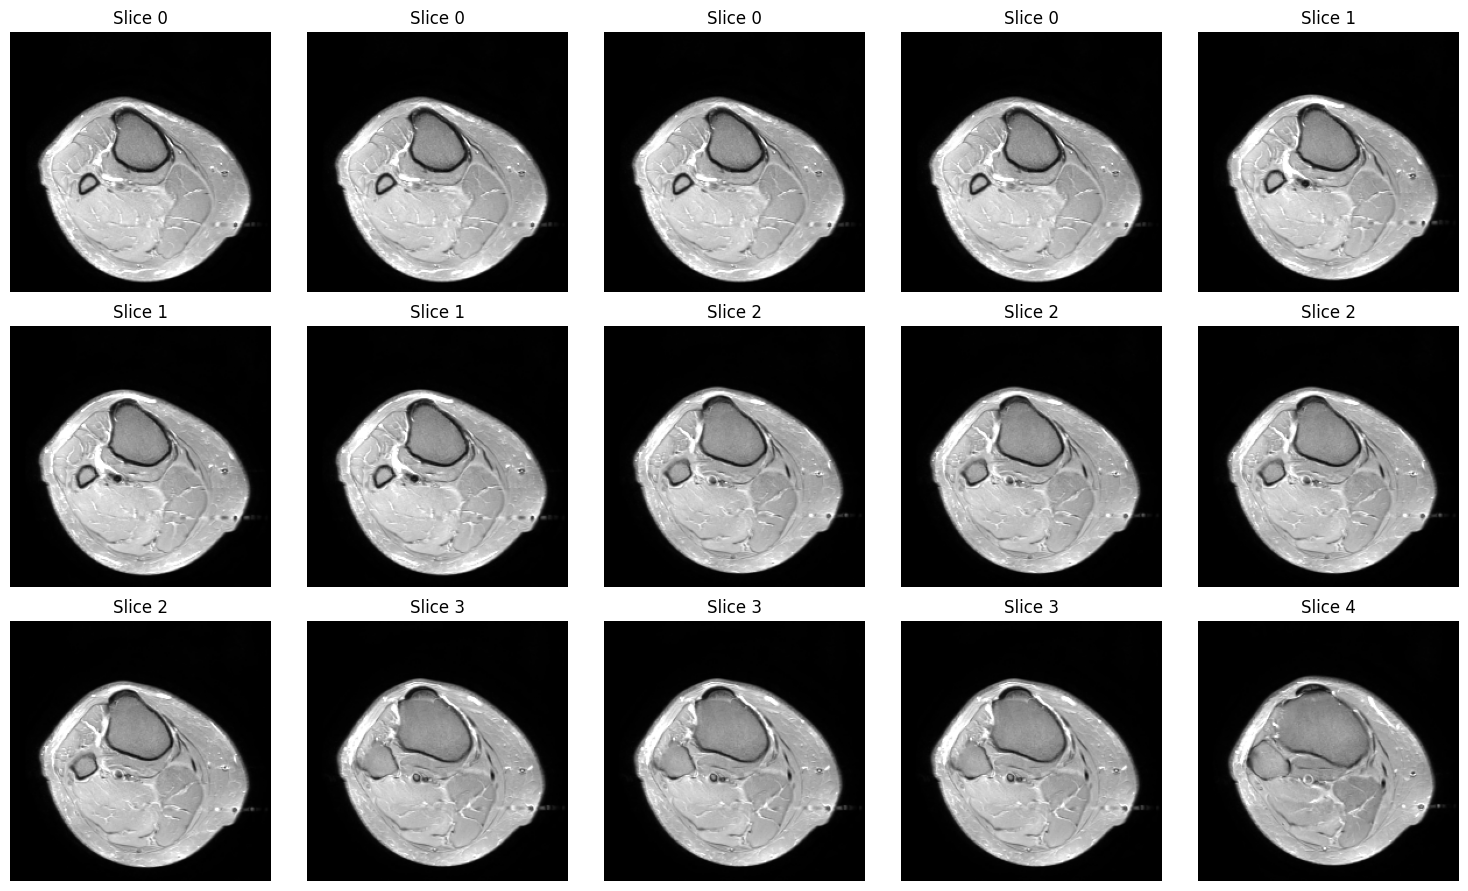

In [5]:
# Verify the very last processed file exists
if 'save_path' in locals() and os.path.exists(save_path):
    print(f"Visualizing: {save_path}")
    
    # Load the compressed volume back into memory
    with np.load(save_path) as data:
        sagittal_volume = data['vol']

    # Dynamically generate indices based on the actual length of the array
    num_slices = len(sagittal_volume)
    print(f"Volume shape: {sagittal_volume.shape}")
    
    indices = np.linspace(0, num_slices - 1, 15, dtype=int)

    fig, axes = plt.subplots(3, 5, figsize=(15, 9))

    for ax, idx in zip(axes.flat, indices):
        ax.imshow(sagittal_volume[idx], cmap="gray")
        ax.set_title(f"Slice {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No volume was successfully saved to visualize.")

# CNN traning

In [4]:
import torchvision.models as models
import torch.nn as nn

def get_knee_cnn_model(num_classes=1):
    # Load a pretrained ConvNeXt-Tiny backbone
    model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
    
    # ConvNeXt's classification head is a Sequential block. 
    # Index 0 is LayerNorm, Index 1 is Flatten, and Index 2 is the Linear layer.
    in_features = model.classifier[2].in_features
    
    # Replace the final linear layer for our specific binary/multi-label output
    model.classifier[2] = nn.Linear(in_features, num_classes)
    
    return model

*7-11-15:53*

In [ ]:
import pandas as pd

# Load the tracking file your script automatically saved
manifest = pd.read_csv("/kaggle/working/my_cache/manifest.csv")

# Count the number of unique patients (StudyInstanceUIDs)
exact_patients = manifest['StudyInstanceUID'].nunique()

print(f"Exact number of patients processed: {exact_patients}")

In [21]:
import os
import shutil

# 1. Check Total Kaggle Working Disk Space
total, used, free = shutil.disk_usage("/kaggle/working")
print(f"--- KAGGLE DISK USAGE ---")
print(f"Total Disk allowed: {total / (1024**3):.2f} GB")
print(f"Used Disk so far:   {used / (1024**3):.2f} GB")
print(f"Free Disk remaining: {free / (1024**3):.2f} GB\n")

# 2. Check the exact size of your 17 patients
def get_dir_size(path):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size

cache_size_mb = get_dir_size("/kaggle/working/my_cache") / (1024**2)
patients_processed = 17

print(f"--- YOUR DATA USAGE ---")
print(f"Total size of 17 patients: {cache_size_mb:.2f} MB")

# 3. Predict the 1500 patient run
if patients_processed > 0:
    avg_per_patient = cache_size_mb / patients_processed
    print(f"Average size per patient:  {avg_per_patient:.2f} MB")
    
    predicted_1500_mb = avg_per_patient * 1500
    print(f"\n--- PREDICTION ---")
    print(f"1,500 patients will take roughly: {predicted_1500_mb / 1024:.2f} GB")

--- KAGGLE DISK USAGE ---
Total Disk allowed: 19.52 GB
Used Disk so far:   5.04 GB
Free Disk remaining: 14.46 GB

--- YOUR DATA USAGE ---
Total size of 17 patients: 5037.74 MB
Average size per patient:  296.34 MB

--- PREDICTION ---
1,500 patients will take roughly: 434.09 GB


In [23]:
import os
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

# 1. The Real Target Columns from your CSV
TARGET_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

class Knee25DDataset(Dataset):
    def __init__(self, df, cache_dir, target_cols, plane="Sagittal", transform=None):
        self.df = df.reset_index(drop=True)
        self.cache_dir = cache_dir
        self.target_cols = target_cols
        self.plane = plane
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        uid = row["StudyInstanceUID"]
        
        npz_path = os.path.join(self.cache_dir, str(uid), f"{self.plane}.npz")
        
        try:
            with np.load(npz_path) as data:
                volume = data['vol']  
        except Exception:
            volume = np.zeros((3, 224, 224), dtype=np.uint8)

        num_slices = volume.shape[0]
        
        # 2.5D Trick
        if num_slices >= 3:
            mid = num_slices // 2
            img_2d = volume[mid-1 : mid+2] 
        elif num_slices > 0:
            img_2d = np.repeat(volume, 3, axis=0)[:3] 
        else:
            img_2d = np.zeros((3, 224, 224), dtype=np.uint8)

        img_tensor = torch.tensor(img_2d, dtype=torch.float32) / 255.0

        if self.transform:
            img_tensor = self.transform(img_tensor)

        # Extracting the 12 probabilities from the CSV
        # Extracting the 12 probabilities and filling missing blanks with 0.
        labels = pd.to_numeric(row[self.target_cols], errors='coerce').fillna(0.0).values.astype(np.float32)
        label_tensor = torch.tensor(labels, dtype=torch.float32)

        return img_tensor, label_tensor

# 2. Run the Connection Test
print("Testing PyTorch Dataset connection with real targets...")

test_dataset = Knee25DDataset(
    df=train_df.head(4), 
    cache_dir=CACHE_DIR,
    target_cols=TARGET_COLS,
    plane="Sagittal"
)

test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False)
images, labels = next(iter(test_loader))

print("\nSuccess! Here is what ConvNeXt will see:")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print(f"Number of target injuries: {labels.shape[1]}")

Testing PyTorch Dataset connection with real targets...

Success! Here is what ConvNeXt will see:
Images shape: torch.Size([2, 3, 224, 224])
Labels shape: torch.Size([2, 12])
Number of target injuries: 12


In [24]:
#old traning dummy 

import timm
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm

# 1. Configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 12  # Your 12 injury columns
EPOCHS = 2        # Just a quick test

# 2. Initialize Model, Loss, and Optimizer
print(f"Loading ConvNeXt Tiny on {DEVICE}...")
# This automatically downloads the pre-trained weights and sets the final layer to 12 outputs
model = timm.create_model('convnext_tiny', pretrained=True, num_classes=NUM_CLASSES)
model = model.to(DEVICE)

# BCEWithLogitsLoss is required because your targets are probabilities (0.0 to 1.0)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4)

# 3. The Training Loop
print("\nStarting Dummy Training Loop...")

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    
    # We use the test_loader from your previous cell
    pbar = tqdm(test_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")
    
    for images, labels in pbar:
        # Move data to GPU
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        
        # Core PyTorch Training Steps
        optimizer.zero_grad()               # 1. Clear old gradients
        outputs = model(images)             # 2. Forward pass (get predictions)
        loss = criterion(outputs, labels)   # 3. Calculate error vs the Kaggle CSV
        loss.backward()                     # 4. Backward pass (calculate gradients)
        optimizer.step()                    # 5. Update model weights
        
        # Update progress bar
        running_loss += loss.item()
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
        
    avg_loss = running_loss / len(test_loader)
    print(f"Epoch {epoch+1} completed. Avg Loss: {avg_loss:.4f}")

print("\nSuccess! The pipeline works end-to-end.")

Loading ConvNeXt Tiny on cuda...

Starting Dummy Training Loop...


Epoch 1/2:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 1 completed. Avg Loss: 0.6706


Epoch 2/2:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 2 completed. Avg Loss: 0.0513

Success! The pipeline works end-to-end.


In [25]:
#on 1500 pateitns data 
import os
import timm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
import pandas as pd
import numpy as np

# 1. Configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

CACHE_DIR = "/kaggle/working/my_cache"
NUM_CLASSES = 12
EPOCHS = 5
BATCH_SIZE = 16  
LEARNING_RATE = 2e-4

TARGET_COLS = ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

# 2. Safely load the exact 1500 patients you processed
# (Assuming train_df is still loaded in your notebook. If not, reload it from your CSV)
manifest = pd.read_csv(os.path.join(CACHE_DIR, "manifest.csv"))
processed_uids = manifest["StudyInstanceUID"].unique()

# Filter train_df to only include the patients we successfully cached
processed_df = train_df[train_df["StudyInstanceUID"].isin(processed_uids)].reset_index(drop=True)
print(f"Found {len(processed_df)} complete patients ready for training.")

# 3. Train/Val Split (80% Train, 20% Val)
train_df_split, val_df_split = train_test_split(processed_df, test_size=0.2, random_state=42)

# Assuming Knee25DDataset is already defined in your notebook from earlier
train_dataset = Knee25DDataset(train_df_split, CACHE_DIR, TARGET_COLS, plane="Sagittal")
val_dataset = Knee25DDataset(val_df_split, CACHE_DIR, TARGET_COLS, plane="Sagittal")

# num_workers=2 speeds up data loading to the GPU
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# 4. Initialize ConvNeXt Tiny
model = timm.create_model('convnext_tiny', pretrained=True, num_classes=NUM_CLASSES).to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

# 5. The Training Loop
best_val_loss = float('inf')

for epoch in range(EPOCHS):
    print(f"\n--- Epoch {epoch+1}/{EPOCHS} ---")
    
    # --- TRAIN ---
    model.train()
    train_loss = 0.0
    pbar_train = tqdm(train_loader, desc="Training")
    
    for images, labels in pbar_train:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        pbar_train.set_postfix({'loss': f"{loss.item():.4f}"})
        
    avg_train = train_loss / len(train_loader)
    
    # --- VALIDATE ---
    model.eval()
    val_loss = 0.0
    
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validating"):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            val_loss += criterion(model(images), labels).item()
            
    avg_val = val_loss / len(val_loader)
    print(f"Train Loss: {avg_train:.4f} | Val Loss: {avg_val:.4f}")
    
    # --- SAVE BEST MODEL ---
    if avg_val < best_val_loss:
        best_val_loss = avg_val
        torch.save(model.state_dict(), "best_convnext_knee.pth")
        print(">>> Validation loss improved! Model saved. <<<")

print("\nPipeline complete. You have a trained ConvNeXt model!")

Using device: cuda
Found 1500 complete patients ready for training.

--- Epoch 1/5 ---


Training:   0%|          | 0/75 [00:00<?, ?it/s]

Validating:   0%|          | 0/19 [00:00<?, ?it/s]

Train Loss: 0.0497 | Val Loss: 0.0352
>>> Validation loss improved! Model saved. <<<

--- Epoch 2/5 ---


Training:   0%|          | 0/75 [00:00<?, ?it/s]

Validating:   0%|          | 0/19 [00:00<?, ?it/s]

Train Loss: 0.0315 | Val Loss: 0.0339
>>> Validation loss improved! Model saved. <<<

--- Epoch 3/5 ---


Training:   0%|          | 0/75 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x791c5cb29bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x791c5cb29bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

KeyboardInterrupt: 